# Лабараторная работа 1. Иерархический кластерный анализ
**Выполнила** Кравцова София

**Цель.** Сегментировать потребителей леденцов на основе опроса о целях потребления леденцов. Ответы на вопросы давались в 5-бальной шкале

**Метод:** иерархический кластерный анализ

In [28]:
# импортируем библиотеки
import pandas as pd
import matplotlib.pyplot as plt
plt.style.use('ggplot')
import seaborn as sns

from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from scipy.spatial.distance import pdist

import os

In [7]:
PATH = os.path.abspath('Задачи для лабораторной_1-3\\labtask1_lollypops\\Леденцы.dat')

# загружаем данные
df = pd.read_csv(PATH, delimiter=';')

## Подготовка

In [8]:
X = df.copy()

In [9]:
X.head() # смотрим, как выглядят данные

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11
0,4,5,5,5,3,3,3,3,3,3,3
1,5,4,5,5,3,3,3,3,3,3,3
2,5,5,4,5,3,3,3,3,3,3,3
3,5,4,5,5,3,3,3,3,3,3,3
4,4,5,5,5,3,3,3,3,3,3,3


In [10]:
X.info()  # смотрим информацию о датасете, какие типы данных и есть ли пропуски

<class 'pandas.DataFrame'>
RangeIndex: 338 entries, 0 to 337
Data columns (total 11 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   V1      338 non-null    int64
 1   V2      338 non-null    int64
 2   V3      338 non-null    int64
 3   V4      338 non-null    int64
 4   V5      338 non-null    int64
 5   V6      338 non-null    int64
 6   V7      338 non-null    int64
 7   V8      338 non-null    int64
 8   V9      338 non-null    int64
 9   V10     338 non-null    int64
 10  V11     338 non-null    int64
dtypes: int64(11)
memory usage: 29.2 KB


Все ячейки заполнены числовыми значениями, пропущенных ячеек нет

In [11]:
X.describe()

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11
count,338.000000,338.000000,338.000000,338.000000,338.000000,338.000000,338.000000,338.000000,338.000000,338.000000,338.000000
mean,3.544379,3.526627,3.517751,3.411243,3.207101,3.204142,3.254438,3.289941,3.603550,3.550296,3.565089
std,0.955748,0.956410,0.990150,0.992311,0.867314,0.869725,0.844107,0.821784,0.969682,0.927082,0.942042
min,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000
25%,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000
50%,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000
75%,5.000000,5.000000,5.000000,4.000000,3.000000,3.000000,3.000000,3.000000,5.000000,5.000000,5.000000
max,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000


Данные во всех столбцах находятся в диапозоне от 2 до 5, выбросов за эти пределы нет (что подкрепляется природой данных). Нормализация не нужна

## Кластеризация

In [12]:
# вычисляем матрицу попарных расстояний для всех наблюдений
distances = pdist(X, metric='euclidean')

# выполняем кластеризацию методом Уорда
cl = linkage(distances, method='ward')

## Выбор параметров:
### pdist(metric='euclidean')
Для подсчета попарных расстояний между наблюдениями выбираем евклидово расстояние
- данные одного масштаба, однородные, выбросов нет (числовые значения от 2 до 5), для таких данных подходит евклидово расстояние

### linkage(method='ward')
Считаем расстояния между кластерами методом Уорда
- метод Уорда подходит для сферических компактных кластеров, которые можно ожидать при выделении потребительских сегментов

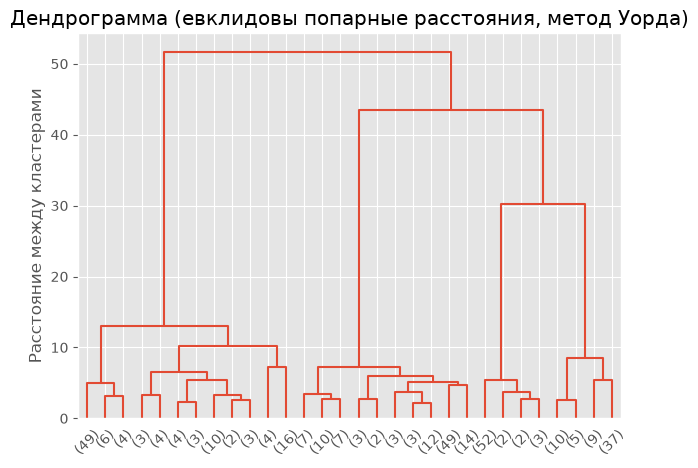

In [13]:
# визуализируем дендрограмму
plt.figure(figsize=(7, 5))
dendrogram(cl, truncate_mode='lastp', p=30, color_threshold=0)
plt.title('Дендрограмма (евклидовы попарные расстояния, метод Уорда)')
plt.ylabel('Расстояние между кластерами')

plt.show()

На дендрограмме можно увидеть 4 отдельные ветви. Предположительно данные можно разделить на 4 кластера. Чтобы удостовериться в этом, построим диаграмму "каменистая осыпь"

<function matplotlib.pyplot.show(close=None, block=None)>

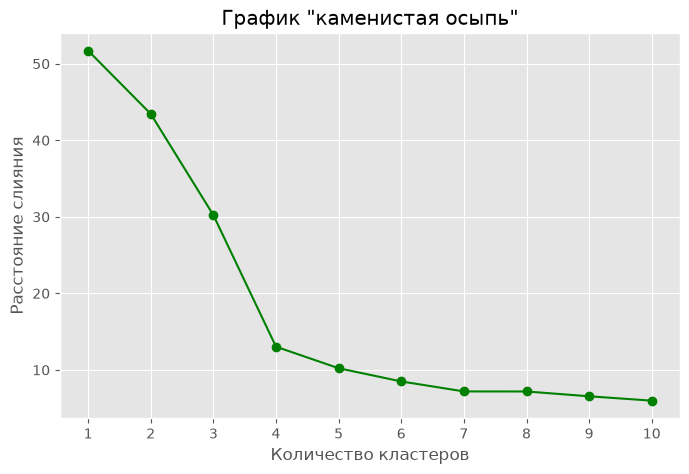

In [14]:
merges = cl[:, 2]  # 3ий столбей матрицы слияний, содержит расстояния слияния 

cluster_count = range(10, 0, -1)  # возможное число кластеров
subset_merges = merges[-10:]

plt.figure(figsize=(8, 5))
plt.plot(cluster_count, subset_merges, '-og')
plt.title('График "каменистая осыпь"')
plt.xlabel('Количество кластеров')
plt.ylabel('Расстояние слияния')
plt.xticks(cluster_count)

plt.show

На графике виден резкий излом в точке 4, следовательно, при переходе от четырех кластеров к трем происходит большой скачок расстояния объединения, разница же между четырьмя и пятью незначительная. Таким образом, оптимальное количество кластеров - 4 

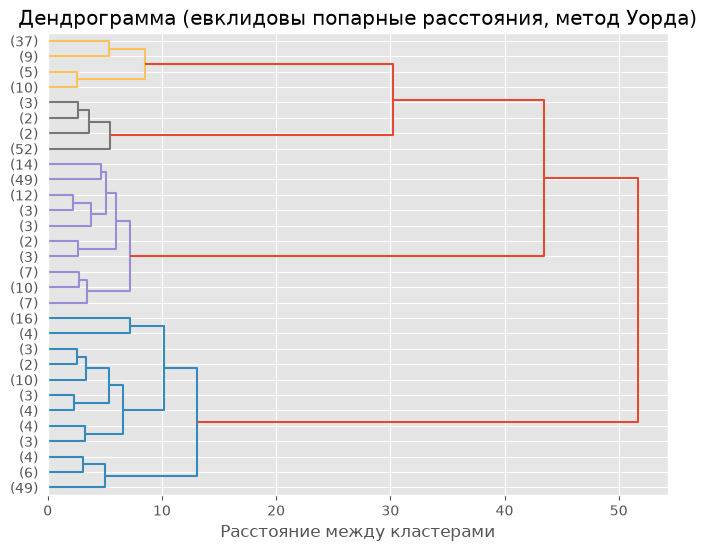

In [15]:
# отрисуем итоговую дендрограмму с выделенными кластерами
plt.figure(figsize=(8, 6))
# color_threshold так же определим по графику "каменистой осыпи"
dendrogram(cl, truncate_mode='lastp', p=30, color_threshold=20, orientation='right')

plt.title('Дендрограмма (евклидовы попарные расстояния, метод Уорда)')
plt.xlabel('Расстояние между кластерами')

plt.show()

In [ ]:
X_labeled = X.copy()

In [23]:
X_labeled['cluster'] = fcluster(cl, t=4, criterion='maxclust') # создаем метки кластеров и добавляем их в новый столбец в датафрейм
# ставим параметр maxclust, т.к. знаем точное число кластеров

## Интерпретация кластеров

In [24]:
X_labeled.groupby('cluster').mean() # считаем среднее значение по каждому вопросу для каждого кластера

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11
cluster,,,,,,,,,,,
1,2.824074,2.833333,2.768519,2.620370,2.611111,2.583333,2.750000,2.916667,4.953704,4.814815,4.861111
2,4.845455,4.800000,4.836364,4.681818,3.036364,3.036364,3.000000,2.990909,3.072727,3.045455,3.045455
3,3.000000,2.966102,2.966102,2.915254,2.915254,2.949153,4.915254,4.915254,3.000000,3.000000,3.000000
4,3.000000,3.000000,3.000000,3.000000,4.852459,4.852459,3.000000,2.918033,2.754098,2.754098,2.754098


Для интерпретации смотрим на то, в каких вопросах (V1-V11) среднее стремится к 5. Это будет означать, что респонденты в основном указывали 5 в ответах на эти вопросы и, следовательно, именно этим можно охарактеризовать причины потребления леденцов для респондентов, попавших в этот кластер

In [25]:
X_labeled.groupby('cluster').size().sort_values(ascending=False)  # смотрим количество записей в каждом кластере

cluster
2    110
1    108
4     61
3     59
dtype: int64

In [ ]:
X_labeled['cluster'].value_counts(normalize=True).mul(100).round(2)  # считаем соотношение кластеров в процентах

cluster
2    32.54
1    31.95
4    18.05
3    17.46
Name: proportion, dtype: float64

### Тепловая карта средних по столбцу

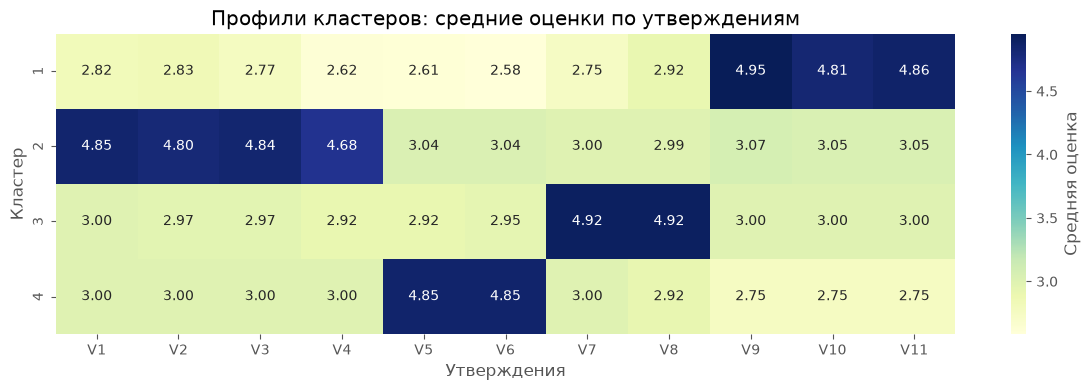

In [30]:
profile = X_labeled.groupby('cluster')[['V1','V2','V3','V4','V5',
                                        'V6','V7','V8','V9','V10','V11']].mean()

plt.figure(figsize=(12, 4))
sns.heatmap(profile, annot=True, fmt='.2f', cmap='YlGnBu',
            cbar_kws={'label': 'Средняя оценка'})
plt.title('Профили кластеров: средние оценки по утверждениям')
plt.xlabel('Утверждения')
plt.ylabel('Кластер')
plt.tight_layout()
plt.show()

### Вопросы, на которые отвечали респонденты (оценка по 5-бальной шкале)
- V1: Я потребляю леденцы, чтобы освежить дыхание
- V2: Я потребляю леденцы, чтобы чувствовать себя увереннее
- V3: Я потребляю леденцы, чтобы освежить полость рта
- V4: Я потребляю леденцы, чтобы избавиться от неприятного вкуса во рту
- V5: Я потребляю леденцы как заменитель других кондитерских изделий
- V6: Я потребляю леденцы, когда мне хочется чего-нибудь сладкого
- V7: Леденцы помогают мне сконцентрироваться
- V8: Я потребляю леденцы, чтобы отвлечься на несколько минут и подумать
- V9: Я потребляю леденцы для того, чтобы облегчить боль в горле
- V10: Я потребляю леденцы для того, чтобы избавиться от заложенности носа
- V11: Я потребляю леденцы для улучшения самочувствия
### Какие вопросы респонденты, причисленные к каждому кластеру, оценивали одинаково высоко:
- кластер 1: V9-11
- кластер 2: V1-4
- кластер 3: V7-8
- кластер 4: V5-6
### Группы респондентов по цели потребления леденцов:
1. леденцы как способ избавиться от неприятного запаха изо рта и почувствовать себя увереннее (кластер 2, 110 записей, "гигиенически-имиджевый")
2. леденцы как способ улучшить физическое самочувствие (боль в горле, заложенность носа) (кластер 1, 108 записей, "лечебно-функциональный")
3. леденцы как источник сахара (кластер 4, 61 запись, "вкусовой")
4. леденцы как способ сконцентрироваться (кластер 3, 59 записей, "психологический")

## Вывод
На основе данных было выделено 4 кластера, характеризующих причины потребления респондентами леденцов: гигиенически-имиджевый, лечебно-функциональный, вкусовой и психологический с процентным соотношением  32.54, 31.95, 18.05 и 17.46 соответственно.\n
Данные разделились на разные по размеру, но довольно однородные и сбалансированные кластеры. Больше половины (64.49%) приходится на 2 кластера, остаток записей на оставшиеся 2. Кластеры хорошо разделимы по содержательным блокам утверждений: каждый кластер имеет выраженный «пик» на своей группе мотивов и заметно ниже оценивает остальные, что подтверждает осмысленность разбиения.

Кластер 1 — «лечебно-функциональный» (108 респондентов, 31.95%). Респонденты этого кластера одинаково высоко оценили утверждения V9–V11, отражающие облегчение симптомов (боль в горле, заложенность носа) и улучшение самочувствия. Для них леденцы — прежде всего средство физической помощи организму, близкое к аптечному продукту. Остальные мотивы (гедонистические, имиджевые, психологические) выражены слабее. Практически это означает акцент на функциональных ингредиентах (мёд, травы, ментол), доверительной коммуникации и аптечном канале продаж.

Кластер 2 — «гигиенически-имиджевый» (110 респондентов, 32.54%). Наибольшие оценки получены по V1–V4: освежение дыхания и полости рта, устранение неприятного вкуса и связанная с этим уверенность в себе. Это самый крупный кластер, и в нём гигиенический мотив неразрывно связан с социальным самоощущением — леденцы выступают инструментом «быть в порядке» в общении. Для этой группы релевантны акцент на свежесть, мятные/цитрусовые вкусы, компактная упаковка «на ходу» и выкладка у кассы.

Кластер 3 — «психологический» (59 респондентов, 17.46%). Высокие оценки по V7–V8 (концентрация и возможность отвлечься, «переключиться» на несколько минут). Это самый малочисленный кластер; леденцы здесь выполняют роль ритуала-паузы в работе или учёбе. Коммуникация для этой группы — «микроперерыв», концентрация, небольшие порции, офисный/учебный контекст.

Кластер 4 — «вкусовой» (61 респондент, 18.05%). Пик по V5–V6: леденцы как заменитель других кондитерских изделий и способ удовлетворить тягу к сладкому. Мотивация гедоническая, связанная со вкусом и удовольствием, а не с функцией или имиджем. Здесь работают вкусовое разнообразие, новинки, яркая упаковка и импульсные покупки.

Таким образом, потребление леденцов неоднородно и распадается на четыре качественно различных мотива: функционально-лечебный, гигиено-имиджевый, психологический (переключение/концентрация) и вкусовой (гедонический). Два первых кластера охватывают около двух третей выборки (64.49%) и отражают «утилитарное» потребление (польза для здоровья и социального самоощущения), тогда как два оставшихся (35.51%) ближе к эмоциональному и ритуальному потреблению. Кластеры различаются преимущественно по содержательным блокам утверждений, а не по случайным колебаниям оценок, что делает интерпретацию устойчивой.